In [1]:
# American Sign Language Classification
# Using Feedforward Neural Network (TensorFlow/Keras)

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split


In [2]:
# Step 1: Load training and testing datasets
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

In [3]:
print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)

Training Dataset Shape: (27455, 785)
Testing Dataset Shape: (7172, 785)


In [4]:

# Step 2: Separate labels and pixel values
X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

In [5]:
# Step 3: Convert labels into 24 consecutive classes
classes = np.sort(np.unique(y_train))
label_map = {label: index for index, label in enumerate(classes)}

y_train = np.array([label_map[label] for label in y_train])
y_test = np.array([label_map[label] for label in y_test])


In [6]:

# Step 4: Normalize pixel values between 0 and 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0


In [7]:

# Step 5: Flatten images (28 x 28 = 784)
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)
print("Input Shape:", X_train.shape)
print("Number of Classes:", len(classes))

Input Shape: (27455, 784)
Number of Classes: 24


In [8]:
print("NaN in X_train:", np.isnan(X_train).sum())
print("NaN in X_test:", np.isnan(X_test).sum())

print("Infinite values:", np.isinf(X_train).sum())

print("Minimum pixel:", X_train.min())
print("Maximum pixel:", X_train.max())

print("Minimum label:", y_train.min())
print("Maximum label:", y_train.max())

NaN in X_train: 0
NaN in X_test: 0
Infinite values: 0
Minimum pixel: 0.0
Maximum pixel: 1.0
Minimum label: 0
Maximum label: 23


In [9]:

# Step 6: Split training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)



In [10]:
# Step 7: Build Feedforward Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),

    tf.keras.layers.Dense(256, activation="relu"),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(64, activation="relu"),

    tf.keras.layers.Dense(24, activation="softmax")
])

In [11]:
# Step 8: Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [12]:
# Step 9: Display model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 243,672 (951.84 KB)

 Trainable params: 243,672 (951.84 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Step 10: Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_data=(X_val, y_val)
)


Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.2644 - loss: 2.4026 - val_accuracy: 0.4325 - val_loss: 1.8255
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5183 - loss: 1.5078 - val_accuracy: 0.5738 - val_loss: 1.3193
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6433 - loss: 1.1099 - val_accuracy: 0.7190 - val_loss: 0.9061
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7269 - loss: 0.8425 - val_accuracy: 0.7505 - val_loss: 0.7600
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7986 - loss: 0.6396 - val_accuracy: 0.8254 - val_loss: 0.5534
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8494 - loss: 0.4890 - val_accuracy: 0.8905 - val_loss: 0.4069
Epoch 7/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8900 - loss: 0.3711 - val_accuracy: 0.8549 - val_loss: 0.4234
Epoch 8/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9288 - loss: 0.2610 - val_accuracy: 0.

In [14]:
# Step 11: Evaluate the model using test dataset
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", test_loss)
print("Test Accuracy: {:.2f}%".format(test_accuracy * 100))


225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7309 - loss: 1.2898

Test Loss: 1.2898286581039429
Test Accuracy: 73.09%


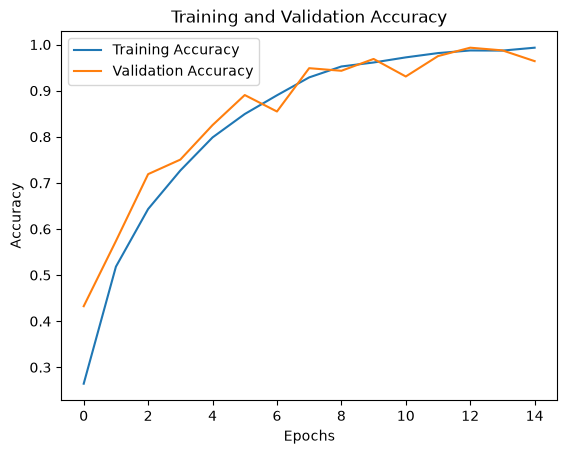

In [15]:
# Step 12: Display accuracy graph
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
# 1. Develop a Feedforward Neural Network using TensorFlow/Keras to
# classify American Sign Language alphabet gestures using the Sign
# Language MNIST dataset. Normalize the pixel values, flatten the images,
# train the model using Dense layers and display the test accuracy